# 第1回 Reduced Order Modeling 演習：POD と DMD

教科書：Brunton & Kutz, *Data-Driven Science and Engineering*, 2nd ed. (2022)。変数名は教科書コード（dynamicslab/databook_python）に合わせています：`X`, `U`, `S`, `VT`, `Atilde`, `Phi`, `lam`。

- データ①：円柱後流 DNS（Re = 100、解析結果の処理＝理想条件）
- データ②：同じ DNS を PIV 風に劣化させたデータ（実験データで何が壊れるか。真値つき）

全セルは Colab の無料枠（GPU なし）で動きます。▶ の付いたセルは、スライドと同じアニメーションをここで再生します（同じ GIF は `figures/anim/`）。▶ のセルは計算が重いので、時間が無ければ飛ばしてかまいません。

## セル0　準備（clone / import）

In [1]:
import os, sys, time
if 'google.colab' in sys.modules and not os.path.exists('rom_utils.py'):
    !git clone https://github.com/ShigoZhihao/waseda-course-rom-1
    %cd waseda-course-rom-1
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, os.getcwd())

import numpy as np
import matplotlib.pyplot as plt
from rom_utils import *
sys.path.insert(0, os.path.join(os.getcwd(), 'scripts'))
from make_animations import show       # ▶ のセルでアニメーションを再生する

os.makedirs('figures/static', exist_ok=True)
plt.rcParams.update({'font.size': 11, 'axes.prop_cycle': plt.cycler(color=THEME)})
def save(fig, name):
    fig.savefig(f'figures/static/{name}.png', dpi=150, bbox_inches='tight')
T0 = time.time()

## セル1　円柱後流を読み込む（p.8）

場を 1 列のベクトルに伸ばし、時刻順に横に並べると、スナップショット行列 $X$（$n \times m$）になります。**列＝1 時刻の場**です。

In [2]:
d1 = load_cylinder('data/cylinder_vort_f32.npz')
vort, x, y, dt = d1['vort'], d1['x'], d1['y'], round(float(d1['dt']), 6)
ny, nx, m = vort.shape
body = (*d1['body'][:2], d1['body'][2])     # 円柱の中心 x, y と半径
X = to_X(vort).astype(np.float64)          # n x m
print('格子 ny x nx =', ny, 'x', nx, '  スナップショット m =', m, '  dt =', dt)
print('X.shape =', X.shape, ' (n = 空間点数, m = 時刻数。n >> m)')

格子 ny x nx = 100 x 225   スナップショット m = 151   dt = 0.2
X.shape = (22500, 151)  (n = 空間点数, m = 時刻数。n >> m)


In [ ]:
# ▶ p.8 のアニメーション（同じ GIF: figures/anim/06_build_X.gif）
show('06_build_X')

## セル2　平均を引く／引かない（p.11）

平均を引かないと、第1モードは平均場になります。平均を引くと、揺らぎのモードが出ます。

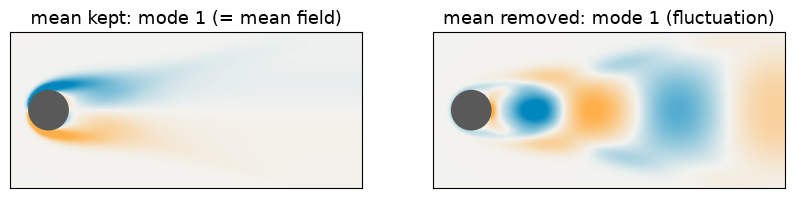

In [4]:
U0, S0, VT0, _ = pod(X, subtract_mean=False)
U, S, VT, xbar = pod(X, subtract_mean=True)
fig, axs = plt.subplots(1, 2, figsize=(10, 2.6))
plot_field(axs[0], to_field(U0[:, 0], ny, nx), x, y, body=body); axs[0].set_title('mean kept: mode 1 (= mean field)')
plot_field(axs[1], to_field(U[:, 0], ny, nx), x, y, body=body);  axs[1].set_title('mean removed: mode 1 (fluctuation)')
save(fig, 'nb02_mean_subtraction'); plt.show()

## セル3　SVD と method of snapshots（p.10）

`np.linalg.svd` の $U$ と、小さい $X^\top X$（$m \times m$）の固有分解から作る $U = X V \Sigma^{-1}$ が同じになることを確かめます。

XtX の大きさ: (151, 151)（X は (22500, 151)）
U（モード1-10）の相対誤差 = 2.97e-13   sigma の最大相対誤差 = 2.55e-15
計算時間: SVD 0.17 s,  method of snapshots 0.05 s


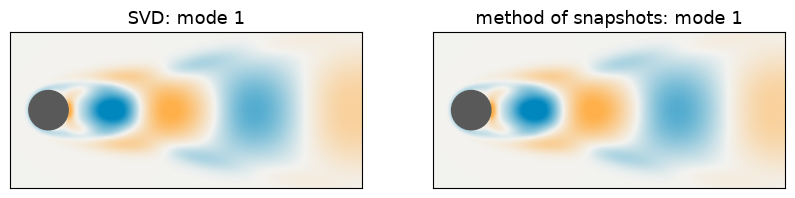

In [5]:
Xc = X - xbar
t = time.time(); U, S, VT = np.linalg.svd(Xc, full_matrices=False); t_svd = time.time() - t
t = time.time(); XtX = Xc.T @ Xc; Us, Ss, VTs = pod_snapshots(Xc); t_snap = time.time() - t

r_chk = 10
sgn = np.sign(np.sum(U[:, :r_chk] * Us[:, :r_chk], axis=0))       # 固有ベクトルの符号はどちらでもよい
err_U = np.linalg.norm(U[:, :r_chk] - Us[:, :r_chk] * sgn) / np.linalg.norm(U[:, :r_chk])
err_S = np.max(np.abs(S[:r_chk] - Ss[:r_chk]) / S[:r_chk])
print(f'XtX の大きさ: {XtX.shape}（X は {Xc.shape}）')
print(f'U（モード1-{r_chk}）の相対誤差 = {err_U:.2e}   sigma の最大相対誤差 = {err_S:.2e}')
print(f'計算時間: SVD {t_svd:.2f} s,  method of snapshots {t_snap:.2f} s')

fig, axs = plt.subplots(1, 2, figsize=(10, 2.6))
plot_field(axs[0], to_field(U[:, 0], ny, nx), x, y, body=body); axs[0].set_title('SVD: mode 1')
plot_field(axs[1], to_field(Us[:, 0] * sgn[0], ny, nx), x, y, body=body); axs[1].set_title('method of snapshots: mode 1')
save(fig, 'nb03_svd_vs_snapshots'); plt.show()

In [ ]:
# ▶ p.10 のアニメーション（同じ GIF: figures/anim/08_U_from_snapshots.gif）
show('08_U_from_snapshots')

## セル4　特異値と累積エネルギー（p.12）

累積エネルギー 90% → r = 4,  95% → r = 5,  99% → r = 7


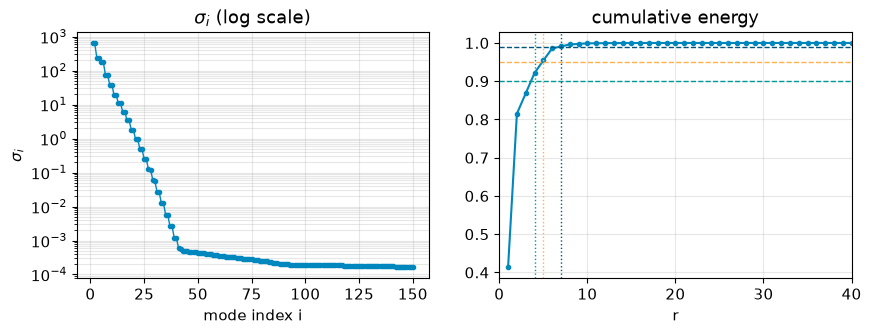

In [7]:
E = energy(S)
r90, r95, r99 = (rank_for_energy(S, q) for q in (0.90, 0.95, 0.99))
print(f'累積エネルギー 90% → r = {r90},  95% → r = {r95},  99% → r = {r99}')
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
plot_sigma(axs[0], S[:-1]); axs[0].set_title(r'$\sigma_i$ (log scale)')
axs[1].plot(np.arange(1, m + 1), E, 'o-', ms=3, color=ACC4)
for q, rq, c in [(0.90, r90, ACC1), (0.95, r95, WARM), (0.99, r99, ACC5)]:
    axs[1].axhline(q, color=c, ls='--', lw=1); axs[1].axvline(rq, color=c, ls=':', lw=1)
axs[1].set_xlim(0, 40); axs[1].set_xlabel('r'); axs[1].set_title('cumulative energy'); axs[1].grid(alpha=.3)
save(fig, 'nb04_sigma_energy'); plt.show()

## セル5　空間モード・時間係数・位相平面（p.9・p.12）

時間係数 $a_i(t) = \sigma_i v_i(t)$。モード1と2は対（ペア）になり、$a_1$–$a_2$ の位相平面は円を描きます。

sigma_1 = 650.1, sigma_2 = 639.3, sigma_2/sigma_1 = 0.983
sigma_3 = 233.6, sigma_4 = 232.0, sigma_4/sigma_3 = 0.993


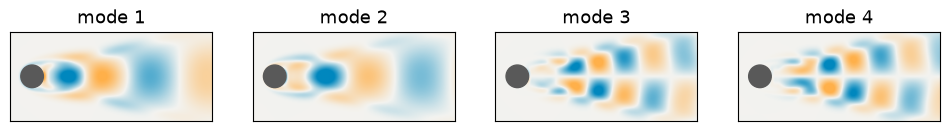

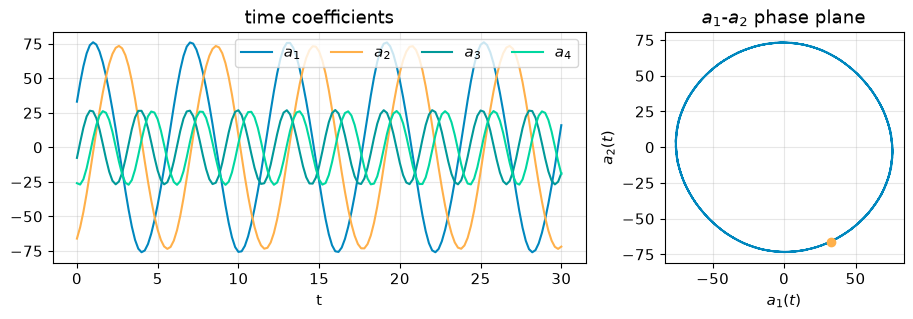

In [8]:
a = (S[:, None] * VT)                      # a_i(t) = sigma_i * v_i(t)
tt = np.arange(m) * dt
print(f'sigma_1 = {S[0]:.1f}, sigma_2 = {S[1]:.1f}, sigma_2/sigma_1 = {S[1]/S[0]:.3f}')
print(f'sigma_3 = {S[2]:.1f}, sigma_4 = {S[3]:.1f}, sigma_4/sigma_3 = {S[3]/S[2]:.3f}')
fig = plt.figure(figsize=(12, 2.4)); plot_modes(fig, U, ny, nx, 4, x, y, body=body); save(fig, 'nb05_modes'); plt.show()
fig, axs = plt.subplots(1, 2, figsize=(11, 3), gridspec_kw={'width_ratios': [2.2, 1]})
for i in range(4):
    axs[0].plot(tt, a[i], label=f'$a_{i+1}$')
axs[0].set_xlabel('t'); axs[0].legend(ncol=4); axs[0].grid(alpha=.3); axs[0].set_title('time coefficients')
plot_phase_plane(axs[1], a[0], a[1]); axs[1].set_title('$a_1$-$a_2$ phase plane')
save(fig, 'nb05_coeffs_phase'); plt.show()

In [ ]:
# ▶ p.9 のアニメーション（同じ GIF: figures/anim/07_modes_and_coeffs.gif）
show('07_modes_and_coeffs')

## セル6　rank-r 再構成誤差（Eckart–Young、p.12）

r = 2, 4, 10 の相対誤差: ['0.430', '0.280', '0.032']


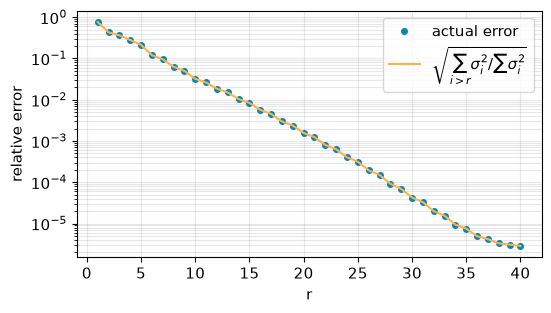

In [10]:
rs = np.arange(1, 41)
err_r = [np.linalg.norm(Xc - U[:, :r] @ np.diag(S[:r]) @ VT[:r]) / np.linalg.norm(Xc) for r in rs]
err_ey = [np.sqrt(np.sum(S[r:]**2) / np.sum(S**2)) for r in rs]       # Eckart–Young の予言値
print('r = 2, 4, 10 の相対誤差:', [f'{err_r[r-1]:.3f}' for r in (2, 4, 10)])
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.semilogy(rs, err_r, 'o', color=ACC4, ms=4, label='actual error')
ax.semilogy(rs, err_ey, '-', color=WARM, label=r'$\sqrt{\sum_{i>r}\sigma_i^2 / \sum\sigma_i^2}$')
ax.set_xlabel('r'); ax.set_ylabel('relative error'); ax.legend(); ax.grid(alpha=.3, which='both')
save(fig, 'nb06_rank_r_error'); plt.show()

In [ ]:
# ▶ p.12 のアニメーション（同じ GIF: figures/anim/10a_rank_r_recon.gif）
show('10a_rank_r_recon')

In [ ]:
# ▶ p.12 のアニメーション（同じ GIF: figures/anim/10b_rotating_pattern.gif）
show('10b_rotating_pattern')

In [ ]:
# ▶ p.12 のアニメーション（同じ GIF: figures/anim/10c_translating_bump.gif）
show('10c_translating_bump')

## セル7　行列の向きの罠（p.11）

`sklearn` の PCA は「行＝サンプル」。`X.T`（行＝時刻）に当てると `components_` が空間モード $U$ に一致します。`X`（行＝空間点）に当てると、時間側 $V$ が出ます。

In [14]:
from sklearn.decomposition import PCA
def match(A, B):          # 列ごとの符号をそろえた相対誤差
    s = np.sign(np.sum(A * B, axis=0)); return np.linalg.norm(A - B * s) / np.linalg.norm(A)
k = 4
p1 = PCA(n_components=k).fit(X.T)           # 行 = 時刻（サンプル）, 列 = 空間点（特徴量）
p2 = PCA(n_components=k).fit(X)             # 行 = 空間点, 列 = 時刻
V2 = np.linalg.svd(X - X.mean(axis=0), full_matrices=False)[2][:k].T
print(f'PCA(X.T).components_.T vs U[:, :{k}] : 相対誤差 {match(U[:, :k], p1.components_.T):.2e}  → 空間モード')
print(f'PCA(X  ).components_.T vs U[:, :{k}] : 形が違う {p2.components_.T.shape} vs {U[:, :k].shape}  → 空間モードではない')
print(f'PCA(X  ).components_.T は行方向の平均を引いた X の右特異ベクトル（時間側）: 相対誤差 {match(V2, p2.components_.T):.2e}')

PCA(X.T).components_.T vs U[:, :4] : 相対誤差 1.24e-14  → 空間モード
PCA(X  ).components_.T vs U[:, :4] : 形が違う (151, 4) vs (22500, 4)  → 空間モードではない
PCA(X  ).components_.T は行方向の平均を引いた X の右特異ベクトル（時間側）: 相対誤差 3.52e-14


## セル8　exact DMD（p.14）

$X' \approx A X$。$\tilde A = U^\top X' V \Sigma^{-1}$（$r \times r$）の固有値 $\lambda$ から周波数と成長率を出します。円柱直径 $D=1$、流速 $U_\infty=1$ なので、周波数 $f$ がそのままストローハル数 $St = fD/U_\infty$ です。

DMD 周波数（正の側、振幅順）St =

 [0.1654 0.3308 0.4962 0.6616 0.827 ]
支配周波数 St = 0.1654,  |lambda| = 1.00000


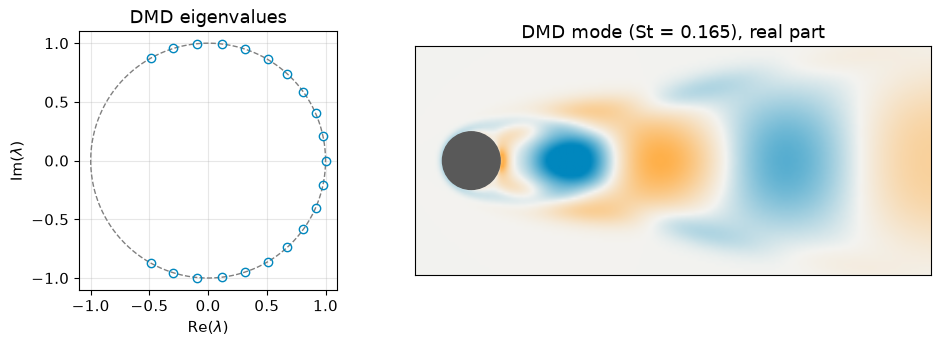

In [15]:
r = 21                                       # 教科書コードと同じランク
lam, Phi, b, freq, growth = exact_dmd(X, dt, r)
order = np.argsort(-np.abs(b))
pos = [i for i in order if freq[i] > 1e-6]
St_dmd = freq[pos[0]]
print('DMD 周波数（正の側、振幅順）St =', np.round(freq[pos[:5]], 4))
print(f'支配周波数 St = {St_dmd:.4f},  |lambda| = {np.abs(lam[pos[0]]):.5f}')
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={'width_ratios': [1, 2]})
plot_dmd_eigs(axs[0], lam); axs[0].set_title('DMD eigenvalues')
plot_field(axs[1], to_field(np.real(Phi[:, pos[0]]), ny, nx), x, y, body=body)
axs[1].set_title(f'DMD mode (St = {St_dmd:.3f}), real part')
save(fig, 'nb08_dmd'); plt.show()

In [ ]:
# ▶ p.14 のアニメーション（同じ GIF: figures/anim/11_dmd_rollout.gif）
show('11_dmd_rollout')

## セル9　POD 係数のスペクトル（周波数は保証されない）と DMD 固有値（離散）（p.15）

POD はエネルギー順に並べた分解で、時間係数の周波数は保証されません。DMD は 1 モード＝1 周波数（＋成長率）です。

この理想的な円柱後流では、POD のモード対も結果的にほぼ 1 つの周波数になります（モード1・2 は渦放出の周波数、3・4 はその 2 倍）。複数の周波数が共存する実験データでは、1 本の POD 時間係数に複数のピークが混ざります（p.15 の博論 Fig. 4.14）。

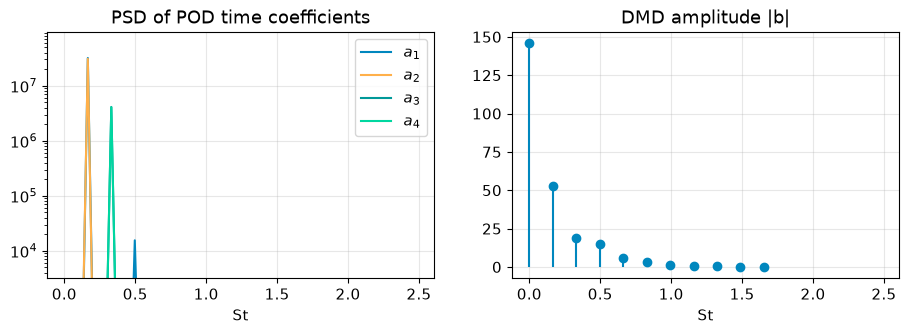

In [17]:
f_fft = np.fft.rfftfreq(m, dt)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.2))
for i in range(4):
    axs[0].semilogy(f_fft, np.abs(np.fft.rfft(a[i]))**2, label=f'$a_{i+1}$')
axs[0].set_ylim(1e-4 * np.abs(np.fft.rfft(a[0])).max()**2, 3 * np.abs(np.fft.rfft(a[0])).max()**2)
axs[0].set_xlabel('St'); axs[0].set_title('PSD of POD time coefficients'); axs[0].legend(); axs[0].grid(alpha=.3)
axs[1].stem(freq[freq >= 0], np.abs(b[freq >= 0]), basefmt=' ')
axs[1].set_xlabel('St'); axs[1].set_title('DMD amplitude |b|'); axs[1].grid(alpha=.3)
axs[1].set_xlim(axs[0].get_xlim())
save(fig, 'nb09_pod_fft_vs_dmd'); plt.show()

## セル10　PIV 風劣化データを読み込む（p.18）

②は①から作りました（`scripts/make_pivlike.py`）。間引き・ノイズ・欠損（NaN）・円柱マスク。PIV が測るのは速度なので、変数は $u, v$ です。

生成パラメータ: {'stride': 4, 'noise': 0.05, 'dropout': 0.05, 'blobs': 3, 'tstride': 1, 'seed': 0}
格子 50 x 113 = 5650 点（① 100 x 225 の 25.1%、元の DNS 449 x 199 の 6.3%）
欠損率（NaN）: 全体 10.6%（うち円柱マスク 2.1%）、円柱の外 8.6%
ノイズ振幅（u の揺らぎ RMS 比）: 0.050


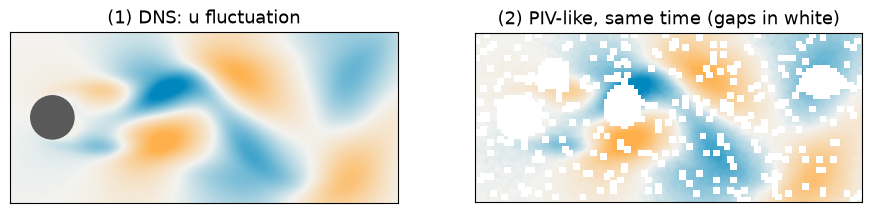

In [18]:
import json
d2 = np.load('data/cylinder_pivlike_f32.npz')
u2, v2, x2, y2, dt2, mask = d2['u'], d2['v'], d2['x'], d2['y'], round(float(d2['dt']), 6), d2['mask']
meta = json.loads(str(d2['meta']))
print('生成パラメータ:', meta['args'])
ny2, nx2, m2 = u2.shape
s = int(meta['args']['stride']) // int(d1['grid_stride'])
ts = int(meta['args']['tstride'])
u_true, v_true = d1['u'][::s, ::s, ::ts].astype(float), d1['v'][::s, ::s, ::ts].astype(float)   # 真値 = ① を同じ格子に間引いたもの
gap = np.isnan(u2)
obs = ~gap
rms = lambda f: np.sqrt(np.mean((f - f.mean(axis=2, keepdims=True))**2))
noise_ratio = np.sqrt(np.mean((u2[obs] - u_true[obs])**2)) / rms(u_true)
print(f'格子 {ny2} x {nx2} = {ny2*nx2} 点（① {ny} x {nx} の {ny2*nx2/(ny*nx):.1%}、元の DNS 449 x 199 の {ny2*nx2/(449*199):.1%}）')
print(f'欠損率（NaN）: 全体 {gap.mean():.1%}（うち円柱マスク {mask.mean():.1%}）、円柱の外 {gap[~mask].mean():.1%}')
print(f'ノイズ振幅（u の揺らぎ RMS 比）: {noise_ratio:.3f}')

k0 = 0
fig, axs = plt.subplots(1, 2, figsize=(11, 2.8))
plot_field(axs[0], d1['u'][:, :, k0] - d1['u'].mean(axis=2), x, y, body=body); axs[0].set_title('(1) DNS: u fluctuation')
import warnings
with warnings.catch_warnings():
    warnings.simplefilter('ignore', RuntimeWarning)       # 円柱の内側は全時刻が欠損
    f2 = np.where(gap[:, :, k0], np.nan, u2[:, :, k0] - np.nanmean(u2, axis=2))
plot_field(axs[1], f2, x2, y2); axs[1].set_title('(2) PIV-like, same time (gaps in white)')
save(fig, 'nb10_piv_vs_dns'); plt.show()

## セル11　欠損の埋め方で結果が変わる（p.18・p.22）

(a) 0 埋め　(b) 時間平均で埋める　(c) Gappy POD（Everson & Sirovich 1995：観測できた点だけでモード係数を最小二乗で決め、欠損を再構成で埋める。これを繰り返す）。真値と比べます。

Gappy POD（r = 10, 10 回反復）: 2.9 s
方法               欠損点の誤差      全体の誤差    σ1-10 の誤差      モード1 の誤差
zero fill         3.169      0.989        0.226      1.39e-02


mean fill         1.007      0.317        0.108      1.00e-03
gappy POD         0.016      0.048        0.001      1.78e-05
（誤差はすべて真値の揺らぎのノルムで割った相対値。モード1 の誤差 = 1 − |内積|）


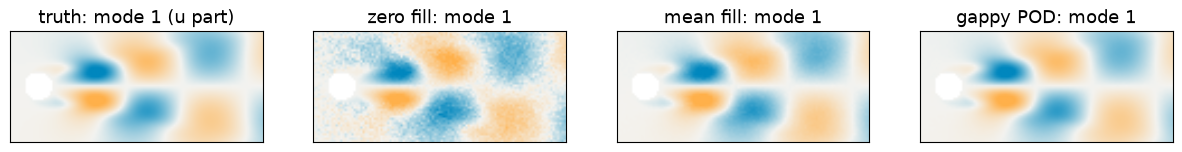

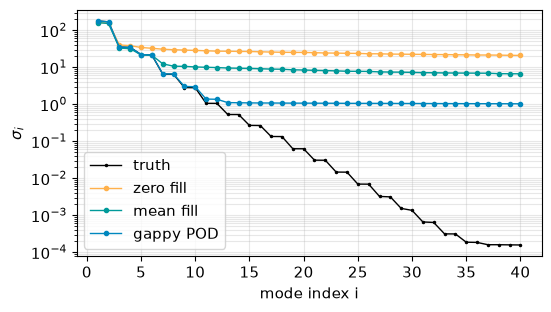

In [19]:
live = ~mask.ravel()
def stack(fu, fv):            # u と v を縦に積む（多変数 POD）。円柱内部は除く
    return np.vstack([fu.reshape(-1, fu.shape[2])[live], fv.reshape(-1, fv.shape[2])[live]])
Xnan = stack(u2.astype(float), v2.astype(float))
Xtrue = stack(u_true, v_true)
G = np.isnan(Xnan)

X0 = np.where(G, 0.0, Xnan)
Xm = np.where(G, np.nanmean(Xnan, axis=1, keepdims=True), Xnan)
t = time.time(); Xg = gappy_fill(Xnan, 10, n_iter=10); t_gappy = time.time() - t

Ut, St_, _, _ = pod(Xtrue)
print(f'Gappy POD（r = 10, 10 回反復）: {t_gappy:.1f} s')
print(f'{"方法":10s} {"欠損点の誤差":>12s} {"全体の誤差":>10s} {"σ1-10 の誤差":>12s} {"モード1 の誤差":>13s}')
results = {}
for name, Xf in [('zero fill', X0), ('mean fill', Xm), ('gappy POD', Xg)]:
    e_gap = np.linalg.norm((Xf - Xtrue)[G]) / np.linalg.norm((Xtrue - Xtrue.mean(1, keepdims=True))[G])
    e_all = np.linalg.norm(Xf - Xtrue) / np.linalg.norm(Xtrue - Xtrue.mean(1, keepdims=True))
    Uf, Sf, _, _ = pod(Xf)
    e_S = np.linalg.norm(Sf[:10] - St_[:10]) / np.linalg.norm(St_[:10])
    e_U1 = 1 - abs(Uf[:, 0] @ Ut[:, 0])
    results[name] = (Sf, Uf)
    print(f'{name:10s} {e_gap:12.3f} {e_all:10.3f} {e_S:12.3f} {e_U1:13.2e}')
print('（誤差はすべて真値の揺らぎのノルムで割った相対値。モード1 の誤差 = 1 − |内積|）')

fig, axs = plt.subplots(1, 4, figsize=(15, 2.6))
nlive = live.sum()
def mode_img(Uc):
    f = np.full(ny2 * nx2, np.nan); f[live] = Uc[:nlive]; return f.reshape(ny2, nx2)
plot_field(axs[0], mode_img(Ut[:, 0]), x2, y2); axs[0].set_title('truth: mode 1 (u part)')
for ax, name in zip(axs[1:], results):
    Uc = results[name][1][:, 0]; Uc = Uc * np.sign(Uc @ Ut[:, 0])
    plot_field(ax, mode_img(Uc), x2, y2); ax.set_title(f'{name}: mode 1')
save(fig, 'nb11_gappy_modes'); plt.show()
fig, ax = plt.subplots(figsize=(6, 3.2))
plot_sigma(ax, St_[:40], label='truth', color='k', marker='.')
for (name, (Sf, _)), c in zip(results.items(), [WARM, ACC1, ACC4]):
    plot_sigma(ax, Sf[:40], label=name, color=c, marker='o')
ax.legend(); save(fig, 'nb11_gappy_sigma'); plt.show()

In [ ]:
# ▶ p.18 のアニメーション（同じ GIF: figures/anim/14b_gappy_fill.gif）
show('14b_gappy_fill')

In [ ]:
# ▶ p.18 のアニメーション（同じ GIF: figures/anim/14a_pvc_orbit.gif）
show('14a_pvc_orbit')

In [ ]:
# ▶ p.22 のアニメーション（同じ GIF: figures/anim/17_deim_greedy.gif）
show('17_deim_greedy')

## セル12　同じ `pod()` を②に当てる（p.18）

ノイズがあると、小さい特異値が「ノイズ床」で止まり、それより先は減衰しなくなります。

- 90〜99% の累積エネルギーで決める r は、ここではほとんど変わりません（ノイズのエネルギーは全体のごく一部）。
- 差が出るのは、ノイズ床より下にある小さなモードです。99.9% の列と図を見て、「どこまでが流れで、どこからがノイズか」を考えてください。

                 90%   95%   99%  99.9%
truth (u, v)       2     3     5     7
(2) gappy          2     3     6    75


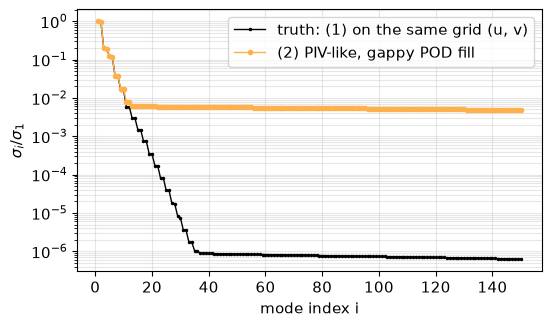

In [23]:
Sg = results['gappy POD'][0]
print(f'{"":14s}{"90%":>6s}{"95%":>6s}{"99%":>6s}{"99.9%":>7s}')
for name, Sx in [('truth (u, v)', St_), ('(2) gappy', Sg)]:
    print(f'{name:14s}' + ''.join(f'{rank_for_energy(Sx, q):6d}' for q in (0.90, 0.95, 0.99, 0.999)))
fig, ax = plt.subplots(figsize=(6, 3.4))
plot_sigma(ax, St_[:-1] / St_[0], label='truth: (1) on the same grid (u, v)', color='k', marker='.')
plot_sigma(ax, Sg[:-1] / Sg[0], label='(2) PIV-like, gappy POD fill', color=WARM, marker='o')
ax.set_ylabel(r'$\sigma_i / \sigma_1$'); ax.legend()
save(fig, 'nb12_sigma_noise_floor'); plt.show()

## セル13　同じ `exact_dmd()` を②に当てる（p.18・p.15）

周波数（固有値の角度）はほぼ一致します。成長率（固有値の半径）は、主要な渦放出のモードではほぼ 1 のままで、弱いモードほどノイズで減衰側（単位円の内側）に寄ります（Dawson et al. 2016）。

支配周波数 St: 真値 0.1654  ②  0.1654  （相対差 0.00%）
その固有値の |lambda|: 真値 1.0000  ②  1.0000
|lambda| の中央値（全 21 個）: 真値 1.0000  ②  0.9963


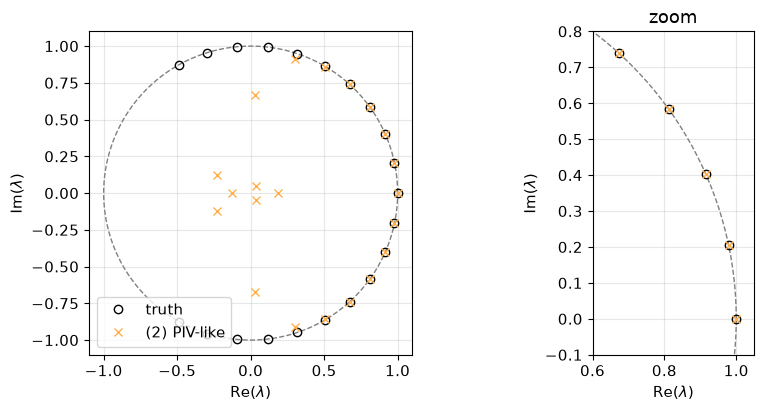

In [24]:
r2 = 21
lam_t, Phi_t, b_t, f_t, g_t = exact_dmd(Xtrue, dt2, r2)
lam_g, Phi_g, b_g, f_g, g_g = exact_dmd(Xg, dt2, r2)
def dominant(fr, bb):
    o = [i for i in np.argsort(-np.abs(bb)) if fr[i] > 1e-6]; return o[0]
it, ig = dominant(f_t, b_t), dominant(f_g, b_g)
print(f'支配周波数 St: 真値 {f_t[it]:.4f}  ②  {f_g[ig]:.4f}  （相対差 {abs(f_g[ig]-f_t[it])/f_t[it]:.2%}）')
print(f'その固有値の |lambda|: 真値 {abs(lam_t[it]):.4f}  ②  {abs(lam_g[ig]):.4f}')
print(f'|lambda| の中央値（全 {r2} 個）: 真値 {np.median(abs(lam_t)):.4f}  ②  {np.median(abs(lam_g)):.4f}')
fig, axs = plt.subplots(1, 2, figsize=(10, 4.2))
for ax in axs:
    plot_dmd_eigs(ax, lam_t, color='k', label='truth', marker='o')
    plot_dmd_eigs(ax, lam_g, color=WARM, label='(2) PIV-like', marker='x', circle=False)
axs[1].set_xlim(0.6, 1.05); axs[1].set_ylim(-0.1, 0.8); axs[1].set_title('zoom')
axs[0].legend(loc='lower left')
save(fig, 'nb13_dmd_eigs_piv'); plt.show()

## セル14　ノイズ実験（宿題用、p.15）

円柱の渦度に白色ノイズを足すと、DMD 固有値が単位円の内側（減衰側）にずれます。

ノイズ   0%: |lambda| の中央値 = 1.0000


ノイズ   5%: |lambda| の中央値 = 0.9999


ノイズ  10%: |lambda| の中央値 = 0.9992
ノイズ  20%: |lambda| の中央値 = 0.9976


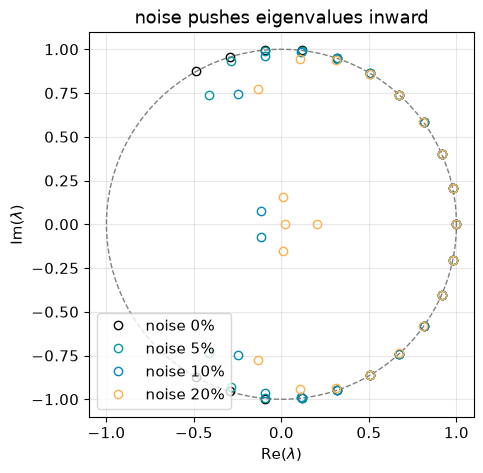

In [25]:
rng = np.random.default_rng(0)
levels = [0.0, 0.05, 0.1, 0.2]
sx = np.sqrt(np.mean(Xc**2))
fig, ax = plt.subplots(figsize=(5, 5))
for lv, c in zip(levels, ['k', ACC1, ACC4, WARM]):
    lam_n = exact_dmd(X + lv * sx * rng.standard_normal(X.shape), dt, r)[0]
    plot_dmd_eigs(ax, lam_n, color=c, label=f'noise {lv:.0%}', circle=(lv == 0))
    print(f'ノイズ {lv:4.0%}: |lambda| の中央値 = {np.median(np.abs(lam_n)):.4f}')
ax.legend(loc='lower left'); ax.set_title('noise pushes eigenvalues inward')
save(fig, 'nb14_noise_eigs'); plt.show()

In [ ]:
# ▶ p.15 のアニメーション（同じ GIF: figures/anim/12_noise_eigs.gif）
show('12_noise_eigs')

In [ ]:
# ▶ p.24 のアニメーション（同じ GIF: figures/anim/19_manifold_vs_subspace.gif）
show('19_manifold_vs_subspace')

In [28]:
print(f'セル0〜14 の実行時間（▶ を含む）: {time.time() - T0:.1f} s')

セル0〜14 の実行時間（▶ を含む）: 99.7 s


## セル15　宿題

1. セル8 の `r` を 5, 11, 41 に変えて、固有値と周波数がどう変わるかを見る。
2. `degrade_to_piv(u, v, stride, noise, dropout, blobs, tstride, seed)` の `noise` を 0〜0.2 に振り、セル11〜13 をもう一度回す。
3. ②の $u, v$ から差分で渦度を出す（ノイズが増幅されることを確かめる）。
4. 自分のデータを `(ny, nx, m)` の形に整形し、`to_X()` → `pod()` → `exact_dmd()` を回す。

In [29]:
# 例：ノイズ 10%、欠損 10% で②を作り直す。実行後、セル11〜13 をもう一度回す（セル10 は回さない）
# Xg_, Yg_ = np.meshgrid(x, y)
# body_mask = Xg_**2 + Yg_**2 <= d1['body'][2]**2          # 円柱の内側
# u2, v2, mask, (u_true, v_true) = degrade_to_piv(d1['u'], d1['v'], stride=s, noise=0.10, dropout=0.10,
#                                                 blobs=3, tstride=1, seed=1, body=body_mask)